# 05 · Fenotipo residual — ¿hay un segundo diagnóstico?

## Pregunta biológica

**¿Qué rasgos del paciente NO explica MVA, y alguno exige un segundo diagnóstico?**

Importa porque la nefrocalcinosis está **presente desde el nacimiento**. La del prematuro es
adquirida y postnatal —se desarrolla en semanas de furosemida, nutrición parenteral y carga de
calcio—. Si está al nacer es antenatal, y **el prior se invierte**.

## La trampa que este notebook existe para evitar

El modo B midió que varios rasgos aportan poco soporte semántico al modelo MVA. La lectura
tentadora sería: *«MVA no los explica, luego hay un segundo diagnóstico»*.

**Sería convertir la incompletitud de una base de datos en biología.** El retraso de
crecimiento aparece en el **93,5 %** de los casos de MVA1: no es un residual misterioso.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


## Método · la pregunta correcta no es el score, es la pertenencia

La contribución *leave-one-out* **no** es el soporte absoluto de un término: con Best Match
Average, retirar un término que puntúa por debajo de la media **sube** el promedio. Así que la
medida correcta es **si el término está anotado en el modelo de enfermedad**.

In [2]:
PREP = pickle.load(io.open("work/hpo/prepared.pkl", "rb"))
mva = [m for m in PREP["models"] if m.disease_id == "OMIM:257300"]
terms = mva[0].terms if mva else set()
print(f"  modelo OMIM:257300 (MVA1) · {mva[0].n_raw} terminos anotados antes de propagar")

PROBAND = [
 ("HP:0002859", "Rabdomiosarcoma",           "38,7 % (malignidad)"),
 ("HP:0004322", "Talla baja",                "93,5 % (crecimiento)"),
 ("HP:0001518", "Pequeno para edad gest.",   "93,5 % (crecimiento)"),
 ("HP:0001508", "Fallo de medro",            "93,5 % (crecimiento)"),
 ("HP:0001622", "Parto prematuro",           "no cuantificado"),
 ("HP:0003202", "Atrofia muscular",          "no cuantificado"),
 ("HP:0000121", "Nefrocalcinosis",           "NO — la serie reporta disfuncion renal generica 12,9 %"),
]
print()
print(f"  {'rasgo':<26}{'anotado en HPO':>16}{'literatura MVA1':>44}")
for hid, lab, lit in PROBAND:
    print(f"  {lab:<26}{('SI' if hid in terms else 'NO'):>16}{lit:>44}")

  modelo OMIM:257300 (MVA1) · 59 terminos anotados antes de propagar

  rasgo                       anotado en HPO                             literatura MVA1
  Rabdomiosarcoma                         SI                         38,7 % (malignidad)
  Talla baja                              SI                        93,5 % (crecimiento)
  Pequeno para edad gest.                 SI                        93,5 % (crecimiento)
  Fallo de medro                          NO                        93,5 % (crecimiento)
  Parto prematuro                         NO                             no cuantificado
  Atrofia muscular                        NO                             no cuantificado
  Nefrocalcinosis                         NONO — la serie reporta disfuncion renal generica 12,9 %


### Figura principal 1 · las dos comprobaciones, cruzadas

Un rasgo solo es **residual de verdad** si falla las **dos**: no anotado en el modelo HPO **y**
no respaldado por la literatura de MVA1.

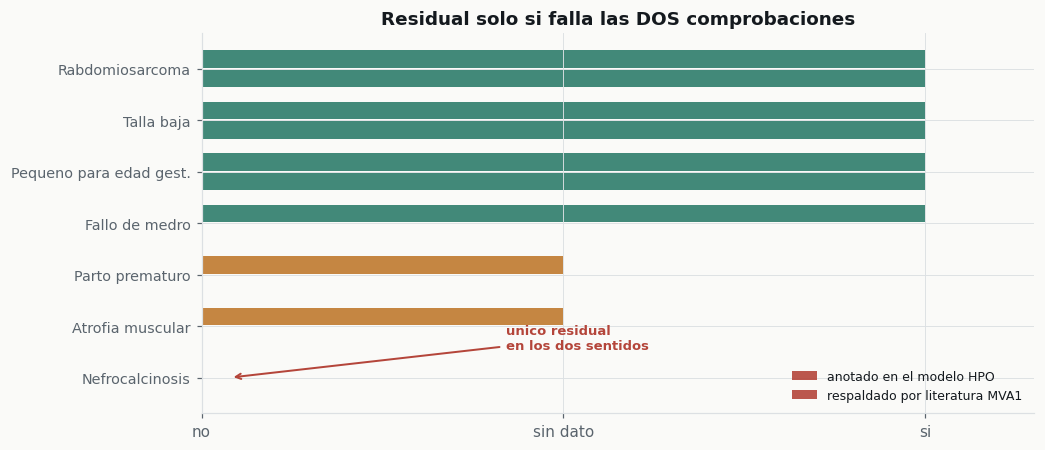

> **Figura principal 1 · anotacion HPO frente a literatura**  
> `EXP-018 · EXP-019` · **EXTERNAL**  
> *Qué enseña:* de los cuatro rasgos con bajo soporte semantico, tres se explican por hueco de anotacion o falta de dato. Fallo de medro NO esta anotado pero la literatura lo cubre al 93,5 %. Solo la nefrocalcinosis carece de anotacion Y de respaldo.  
> **Qué NO demuestra:** que la nefrocalcinosis exija un segundo diagnostico. Que MVA no la describa no implica que no pueda causarla: las series son pequenas y con sesgo de publicacion.  
> procedencia: `corpus HPO local + Neurol Sci 2022, DOI 10.1007/s10072-022-06247-w`

In [3]:
LITOK = {"HP:0002859": 1, "HP:0004322": 1, "HP:0001518": 1, "HP:0001508": 1,
         "HP:0001622": 0.5, "HP:0003202": 0.5, "HP:0000121": 0}
fig, ax = plt.subplots(figsize=(9.6, 4.2))
labels = [p[1] for p in PROBAND][::-1]
ann = [1 if p[0] in terms else 0 for p in PROBAND][::-1]
lit = [LITOK[p[0]] for p in PROBAND][::-1]
y = np.arange(len(labels))
ax.barh(y - 0.19, ann, 0.34, color=[fl.ALIVE if a else fl.DEAD for a in ann],
        alpha=0.9, label="anotado en el modelo HPO")
ax.barh(y + 0.19, lit, 0.34, color=[fl.ALIVE if l == 1 else (fl.OPEN if l else fl.DEAD)
                                     for l in lit], alpha=0.9, label="respaldado por literatura MVA1")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9.4)
ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["no", "sin dato", "si"])
ax.set_xlim(0, 1.15)
ax.legend(fontsize=8.2, frameon=False, loc="lower right")
ax.set_title("Residual solo si falla las DOS comprobaciones")
ax.annotate("unico residual\nen los dos sentidos", xy=(0.04, 0), xytext=(0.42, 0.55),
            fontsize=8.6, color=fl.DEAD, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=fl.DEAD, lw=1.3))

fl.done(fig, "Figura principal 1 · anotacion HPO frente a literatura", "EXP-018 · EXP-019",
        "EXTERNAL",
        "de los cuatro rasgos con bajo soporte semantico, tres se explican por hueco de "
        "anotacion o falta de dato. Fallo de medro NO esta anotado pero la literatura lo "
        "cubre al 93,5 %. Solo la nefrocalcinosis carece de anotacion Y de respaldo.",
        "que la nefrocalcinosis exija un segundo diagnostico. Que MVA no la describa no "
        "implica que no pueda causarla: las series son pequenas y con sesgo de publicacion.",
        prov="corpus HPO local + Neurol Sci 2022, DOI 10.1007/s10072-022-06247-w")

> **Consecuencia para el proyecto:** el argumento de diagnóstico mixto **se estrecha de
> cuatro rasgos a uno**. Más débil en número y mucho más fuerte en calidad, porque ese sí
> resiste las dos comprobaciones.

## Resultado primario 2 · el barrido del panel renal

Con el cruce de alelos **ya corregido**, que era la razón real para repetirlo: la corrección
recuperó 420 posiciones y podía haber destapado un alelo renal que antes se perdía.

Y con la comprobación explícita de `MAGED2` que el propio panel exige: es X-ligado recesivo y
en un varón basta **una** variante hemicigota — un filtro «bialélico» la perdería.

In [4]:
from src.paths import patient_vcf
from src.prioritization.genome_wide import load

panel = {l.split("#")[0].strip() for l in io.open("config/panels/nephrocalcinosis.txt",
                                                  encoding="utf-8") if l.split("#")[0].strip()}
rows = load("work/gw/highmod_ann.tsv", patient_vcf())
hits = [v for v in rows if v.gene in panel and v.impact in ("HIGH", "MODERATE")]
seen, uniq = set(), []
for v in hits:
    k = (v.loc, v.allele, v.gene)
    if k not in seen:
        seen.add(k); uniq.append(v)
freqs = sorted([v.max_af for v in uniq if v.max_af is not None])
rare = [v for v in uniq if v.max_af is None or v.max_af < 0.005]
maged2 = [v for v in rows if v.gene == "MAGED2"]
print(f"  genes del panel: {len(panel)}   alelos HIGH/MODERATE: {len(uniq)}")
print(f"  alelo mas raro del panel: {min(freqs)*100:.1f} %")
print(f"  raros al umbral del propio panel (AF < 0,005): {len(rare)}")
print(f"  variantes de MAGED2, cualquier impacto: {len(maged2)}")

  genes del panel: 28   alelos HIGH/MODERATE: 23
  alelo mas raro del panel: 1.0 %
  raros al umbral del propio panel (AF < 0,005): 0
  variantes de MAGED2, cualquier impacto: 0


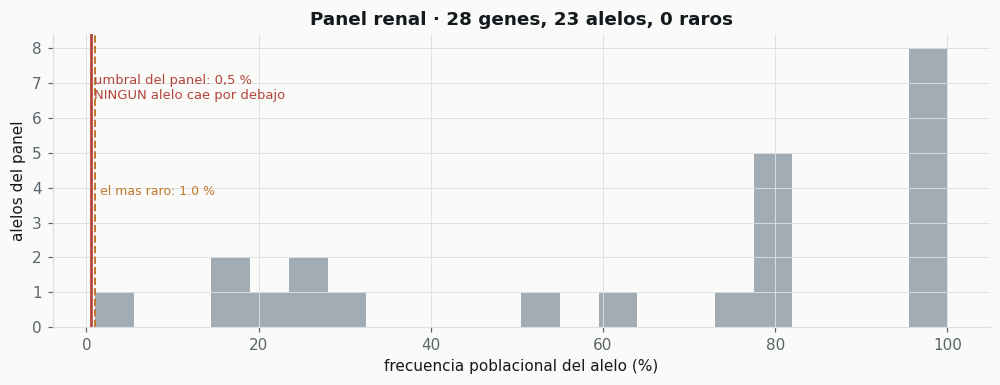

> **Figura principal 2 · el panel renal, en frecuencias**  
> `EXP-017` · **MEASURED**  
> *Qué enseña:* los 23 alelos HIGH/MODERATE del panel son polimorfismos comunes. El mas raro esta al 1.0 %, diez veces por encima del umbral del propio panel. Las dos start_lost de alto impacto que llamaron la atencion estan al 51 % y 81 %. Y MAGED2 no aporta NINGUNA variante (0).  
> **Qué NO demuestra:** que se haya descartado una tubulopatia. Es un barrido CODIFICANTE: no ve variantes reguladoras, intronicas profundas ni estructurales, y esas dependen de EXP-012, bloqueado.  
> procedencia: `config/panels/nephrocalcinosis.txt + cruce de alelos corregido`

In [5]:
fig, ax = plt.subplots(figsize=(9.2, 3.6))
vals = sorted([v.max_af * 100 for v in uniq if v.max_af is not None])
ax.hist(vals, bins=22, color=fl.FLOW, alpha=0.8)
ax.axvline(0.5, color=fl.DEAD, lw=1.8)
ax.text(0.9, ax.get_ylim()[1] * 0.78,
        "umbral del panel: 0,5 %\nNINGUN alelo cae por debajo",
        fontsize=8.6, color=fl.DEAD)
ax.axvline(min(vals), color=fl.OPEN, ls="--", lw=1.3)
ax.text(min(vals) + 0.6, ax.get_ylim()[1] * 0.45, f"el mas raro: {min(vals):.1f} %",
        fontsize=8.2, color=fl.OPEN)
ax.set_xlabel("frecuencia poblacional del alelo (%)")
ax.set_ylabel("alelos del panel")
ax.set_title(f"Panel renal · {len(panel)} genes, {len(uniq)} alelos, 0 raros")

fl.done(fig, "Figura principal 2 · el panel renal, en frecuencias", "EXP-017", "MEASURED",
        f"los {len(uniq)} alelos HIGH/MODERATE del panel son polimorfismos comunes. El mas "
        f"raro esta al {min(vals):.1f} %, diez veces por encima del umbral del propio panel. "
        "Las dos start_lost de alto impacto que llamaron la atencion estan al 51 % y 81 %. "
        f"Y MAGED2 no aporta NINGUNA variante ({len(maged2)}).",
        "que se haya descartado una tubulopatia. Es un barrido CODIFICANTE: no ve variantes "
        "reguladoras, intronicas profundas ni estructurales, y esas dependen de EXP-012, "
        "bloqueado.",
        prov="config/panels/nephrocalcinosis.txt + cruce de alelos corregido")

## Robustez · la pregunta que decide no es computacional

`aBS` produce **poli**hidramnios severo desde la semana 18–22. La MVA se asocia a
**oligo**hidramnios. **Son opuestos**: una línea de la historia obstétrica decide.

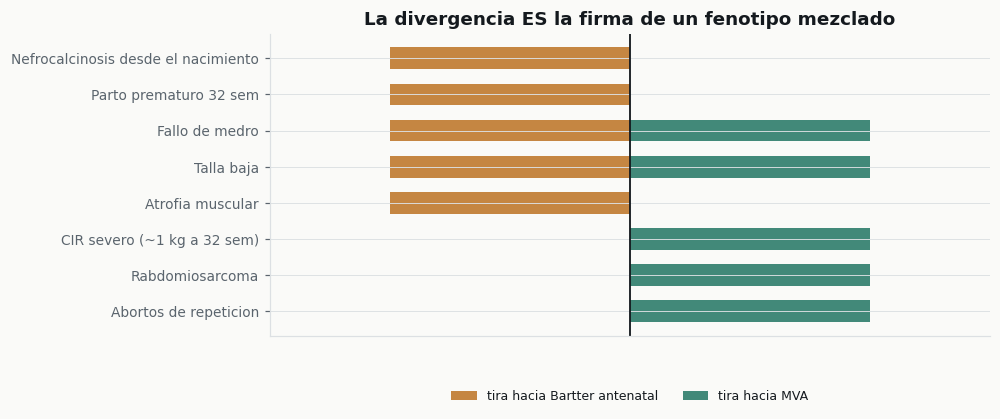

> **Figura de robustez · el fenotipo tira en dos direcciones**  
> `EXP-017` · **EXTERNAL+DERIVED**  
> *Qué enseña:* prematuridad y nefrocalcinosis tiran hacia una tubulopatia antenatal; el CIR severo y el rabdomiosarcoma tiran hacia MVA. Esa divergencia no es ruido: es lo que caracteriza un fenotipo mezclado, y por eso la rama no se cierra.  
> **Qué NO demuestra:** cual de los dos es. Ninguna de estas flechas es una medicion: son priors de literatura. La pregunta que lo decide es clinica, no computacional.  
> procedencia: `brief §8 · Kidney Int 2021 · NEJM 2016 DOI 10.1056/NEJMoa1507629`

In [6]:
EVID = [
 ("Nefrocalcinosis desde el nacimiento", 1, -1),
 ("Parto prematuro 32 sem",              1, -1),
 ("Fallo de medro",                      1,  1),
 ("Talla baja",                          1,  1),
 ("Atrofia muscular",                    1,  0),
 ("CIR severo (~1 kg a 32 sem)",        -1,  1),
 ("Rabdomiosarcoma",                    -1,  1),
 ("Abortos de repeticion",               0,  1),
]
fig, ax = plt.subplots(figsize=(9.2, 4.0))
labs = [e[0] for e in EVID][::-1]
bart = [e[1] for e in EVID][::-1]
mva_ = [e[2] for e in EVID][::-1]
y = np.arange(len(labs))
ax.barh(y, [-abs(b) if b > 0 else 0 for b in bart], color=fl.OPEN, alpha=0.9, height=0.6,
        label="tira hacia Bartter antenatal")
ax.barh(y, [abs(m) if m > 0 else 0 for m in mva_], color=fl.ALIVE, alpha=0.9, height=0.6,
        label="tira hacia MVA")
ax.axvline(0, color=fl.INK, lw=1.2)
ax.set_yticks(y); ax.set_yticklabels(labs, fontsize=9)
ax.set_xlim(-1.5, 1.5); ax.set_xticks([])
ax.legend(fontsize=8.2, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.26))
ax.set_title("La divergencia ES la firma de un fenotipo mezclado")

fl.done(fig, "Figura de robustez · el fenotipo tira en dos direcciones", "EXP-017",
        "EXTERNAL+DERIVED",
        "prematuridad y nefrocalcinosis tiran hacia una tubulopatia antenatal; el CIR severo "
        "y el rabdomiosarcoma tiran hacia MVA. Esa divergencia no es ruido: es lo que "
        "caracteriza un fenotipo mezclado, y por eso la rama no se cierra.",
        "cual de los dos es. Ninguna de estas flechas es una medicion: son priors de "
        "literatura. La pregunta que lo decide es clinica, no computacional.",
        prov="brief §8 · Kidney Int 2021 · NEJM 2016 DOI 10.1056/NEJMoa1507629")

## Decisión

| Rama | Estado |
|---|---|
| Barrido codificante del panel renal | **NEGATIVE** |
| Crecimiento y fallo de medro como residual | **NEGATIVE** — hueco de anotación |
| Parto prematuro | **PARKED** — contextual, sin cuantificar |
| Atrofia muscular | **PARKED** — sin dato para decidir |
| **Nefrocalcinosis** | **UNRESOLVED · residual prioritario** |

### Qué NO demuestra

No descarta una tubulopatía: el barrido es **codificante**. Y no demuestra que la
nefrocalcinosis sea un segundo diagnóstico — solo que MVA no la describe.

### Falsificador, y es gratis

Ya está en la historia clínica: alcalosis metabólica hipopotasémica e hipoclorémica, renina y
aldosterona elevadas, cociente calcio/creatinina urinario alto. **Si son normales, la hipótesis
muere sin gastar un core-hora.**

### Siguiente movimiento — el de mayor valor de todo el proyecto

**¿Hubo polihidramnios u oligohidramnios en el embarazo?** Es un email.